## imports:

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)


# part C :

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
PROC, ART, REP = ROOT/"data/processed", ROOT/"artifacts/tfidf", ROOT/"reports"
ART.mkdir(parents=True, exist_ok=True); REP.mkdir(exist_ok=True)

SPLIT_SEED = 2026
REC_CLASSES  = ["recommended", "not_recommended", "no_idea"]
BAND_CLASSES = ["low", "medium", "high"]
BAND_CODE    = {"low": 0, "medium": 1, "high": 2}

def load(name):   
    return pd.read_csv(PROC/name, dtype=str, keep_default_na=False, na_values=[""])

train, val, test = load("train_supervised.csv"), load("validation.csv"), load("test.csv")
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(n, len(d), "| rec labeled:", d["recommendation_status"].notna().sum(),
          "| band labeled:", d["rating_band"].notna().sum())

train 3555676 | rec labeled: 2944940 | band labeled: 3271658
val 917793 | rec labeled: 788823 | band labeled: 843574
test 917785 | rec labeled: 788823 | band labeled: 843574


### TF-IDF:

In [3]:
VEC_PATH = ART / "tfidf_vectorizer.joblib"
if VEC_PATH.exists() and (ART/"X_test.npz").exists():
    vec = joblib.load(VEC_PATH)
    X_train, X_val, X_test = (sp.load_npz(ART/f"X_{s}.npz") for s in ("train", "val", "test"))
else:
    t0 = time.time()
    vec = TfidfVectorizer(
        ngram_range=(1, 2), min_df=5, max_features=400_000, sublinear_tf=True,
        dtype=np.float32, token_pattern=r"(?u)[\w\u200c]{2,}")   
    vec.fit(train["body"].sample(500_000, random_state=SPLIT_SEED))   #
    print("vocab size:", len(vec.vocabulary_), f"({time.time()-t0:.0f}s)")

    def transform(texts, chunk=200_000):
        parts = Parallel(n_jobs=min(4, os.cpu_count()))(
            delayed(vec.transform)(texts[i:i+chunk]) for i in range(0, len(texts), chunk))
        return sp.vstack(parts, format="csr")

    X_train = transform(train["body"].tolist())
    X_val, X_test = transform(val["body"].tolist()), transform(test["body"].tolist())
    joblib.dump(vec, VEC_PATH)
    for s, X in (("train", X_train), ("val", X_val), ("test", X_test)):
        sp.save_npz(ART/f"X_{s}.npz", X, compressed=False)
    print(f"done in {time.time()-t0:.0f}s")

print(X_train.shape, X_train.nnz)
train = train.drop(columns=["body"], errors="ignore")   

vocab size: 115840 (45s)
done in 165s
(3555676, 115840) 53136203


### metrics:

In [4]:
def evaluate(y_true, y_pred, classes, ordinal=False):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=classes, zero_division=0)
    out = {
        "n": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f.mean()), "macro_precision": float(p.mean()), "macro_recall": float(r.mean()),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "per_class": {c: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]),
                          "support": int(s[i])} for i, c in enumerate(classes)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=classes).tolist(),
    }
    if ordinal:
        t = pd.Series(y_true).map(BAND_CODE).values; q = pd.Series(y_pred).map(BAND_CODE).values
        out["ordinal_distance_error"] = float(np.abs(t - q).mean())
    return out

TASKS = {"recommendation": ("recommendation_status", REC_CLASSES, False),
         "rating_band":    ("rating_band", BAND_CLASSES, True)}
def make_clf(alpha):
    return SGDClassifier(loss="log_loss", alpha=alpha, max_iter=15, tol=1e-3,
                         class_weight="balanced", random_state=SPLIT_SEED)

In [5]:
ALPHAS, TUNE_N = [3e-7, 1e-6, 3e-6, 1e-5, 3e-5], 300_000
best_alpha_full, tuning = {}, {}
for task, (col, classes, _) in TASKS.items():
    idx_tr = np.flatnonzero(train[col].notna().values)
    rng = np.random.RandomState(SPLIT_SEED)
    sub = np.sort(rng.choice(idx_tr, min(TUNE_N, len(idx_tr)), replace=False))
    Xs, ys = X_train[sub], train[col].values[sub]
    idx_va = np.flatnonzero(val[col].notna().values)
    Xv, yv = X_val[idx_va], val[col].values[idx_va]

    rows = []
    for a in ALPHAS:
        clf = make_clf(a).fit(Xs, ys)
        f1 = f1_score(yv, clf.predict(Xv), labels=classes, average="macro", zero_division=0)
        rows.append({"alpha": a, "val_macro_f1": round(f1, 4)}); print(task, a, round(f1, 4))
    tuning[task] = pd.DataFrame(rows)
    best = tuning[task].sort_values("val_macro_f1").iloc[-1]["alpha"]
    best_alpha_full[task] = float(best) * len(sub) / len(idx_tr)
    print(f"→ {task}: best alpha on sample = {best}, scaled for full train = {best_alpha_full[task]:.2e}\n")

e:\maktab seesion\home work\code\project-3\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


recommendation 3e-07 0.658


e:\maktab seesion\home work\code\project-3\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


recommendation 1e-06 0.6745
recommendation 3e-06 0.683
recommendation 1e-05 0.6809
recommendation 3e-05 0.6733
→ recommendation: best alpha on sample = 3e-06, scaled for full train = 3.06e-07



e:\maktab seesion\home work\code\project-3\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


rating_band 3e-07 0.6129


e:\maktab seesion\home work\code\project-3\.venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


rating_band 1e-06 0.6373
rating_band 3e-06 0.6453
rating_band 1e-05 0.6418
rating_band 3e-05 0.6348
→ rating_band: best alpha on sample = 3e-06, scaled for full train = 2.75e-07



### Improved baseline: max_iter=50:

In [6]:
IMPROVED_ALPHAS = [1.5e-6, 2e-6, 3e-6, 4e-6, 5e-6]
improved_results = {}

for task, (col, classes, _) in TASKS.items():
    idx_tr = np.flatnonzero(train[col].notna().values)
    rng = np.random.RandomState(SPLIT_SEED)
    sub = np.sort(rng.choice(idx_tr, min(TUNE_N, len(idx_tr)), replace=False))
    Xs, ys = X_train[sub], train[col].values[sub]
    
    idx_va = np.flatnonzero(val[col].notna().values)
    Xv, yv = X_val[idx_va], val[col].values[idx_va]

    rows = []
    for a in IMPROVED_ALPHAS:
        clf = SGDClassifier(
            loss="log_loss", alpha=a, max_iter=50, tol=1e-3,
            class_weight="balanced", random_state=SPLIT_SEED
        ).fit(Xs, ys)
        f1 = f1_score(yv, clf.predict(Xv), labels=classes, average="macro", zero_division=0)
        rows.append({"alpha": a, "val_macro_f1": round(f1, 4)})
        print(task, a, round(f1, 4))
    
    improved_results[task] = pd.DataFrame(rows)
    best = improved_results[task].sort_values("val_macro_f1").iloc[-1]["alpha"]
    best_alpha_full[task] = float(best) * len(sub) / len(idx_tr)
    print(f"→ {task}: best alpha = {best}, scaled = {best_alpha_full[task]:.2e}\n")

recommendation 1.5e-06 0.679
recommendation 2e-06 0.6803
recommendation 3e-06 0.683
recommendation 4e-06 0.683
recommendation 5e-06 0.6831
→ recommendation: best alpha = 5e-06, scaled = 5.09e-07

rating_band 1.5e-06 0.6383
rating_band 2e-06 0.6419
rating_band 3e-06 0.6453
rating_band 4e-06 0.6464
rating_band 5e-06 0.6471
→ rating_band: best alpha = 5e-06, scaled = 4.58e-07



In [10]:
def make_clf(alpha, max_iter=30):
    return SGDClassifier(loss="log_loss", alpha=alpha, max_iter=max_iter, tol=1e-3,
                         class_weight="balanced", random_state=SPLIT_SEED)

models, results, final_alpha = {}, {}, {}
for task, (col, classes, ordinal) in TASKS.items():
    idx_tr = np.flatnonzero(train[col].notna().values)
    Xt, yt = X_train[idx_tr], train[col].values[idx_tr]
    idx_va = np.flatnonzero(val[col].notna().values)
    Xv, yv = X_val[idx_va], val[col].values[idx_va]

    # دو کاندید alpha روی کل train؛ انتخاب فقط با validation
    best = None
    for tag, a in {"scaled": best_alpha_full[task], "x4": 4 * best_alpha_full[task]}.items():
        clf = make_clf(a).fit(Xt, yt)
        f1 = f1_score(yv, clf.predict(Xv), labels=classes, average="macro", zero_division=0)
        print(f"{task} | alpha={a:.2e} ({tag}) | val macro_f1={f1:.4f}")
        if best is None or f1 > best[0]:
            best = (f1, a, clf)
    _, final_alpha[task], clf = best
    models[task], results[task] = clf, {}

    for split, X, df in (("validation", X_val, val), ("test", X_test, test)):
        idx = np.flatnonzero(df[col].notna().values)
        y_true, pred = df[col].values[idx], clf.predict(X[idx])
        proba = clf.predict_proba(X[idx])
        results[task][split] = evaluate(y_true, pred, classes, ordinal)
        pr = pd.DataFrame({"id": df["id"].values[idx], "y_true": y_true, "y_pred": pred})
        for i, c in enumerate(clf.classes_):
            pr[f"p_{c}"] = proba[:, i]
        pr.to_parquet(REP/f"preds_tfidf_{task}_{split}.parquet", index=False)

    r = results[task]["test"]
    print(f"\n{task} TEST | macro_f1={r['macro_f1']:.4f} acc={r['accuracy']:.4f} "
          f"bal_acc={r['balanced_accuracy']:.4f}" +
          (f" ord_err={r['ordinal_distance_error']:.4f}" if ordinal else ""))
    for c, m in r["per_class"].items():
        print(f"   {c:16s} P={m['precision']:.3f} R={m['recall']:.3f} F1={m['f1']:.3f} n={m['support']}")
    print()

for task, m in models.items():
    joblib.dump(m, ART/f"logreg_{task}.joblib")
json.dump({"final_alpha": final_alpha, "tuning_sample_alpha_grid": ALPHAS, "tune_n": TUNE_N,
           "vectorizer": {"ngram": [1, 2], "min_df": 5, "max_features": 400000,
                          "fit_sample": 500000, "sample_seed": SPLIT_SEED},
           "results": results},
          open(REP/"baseline_metrics.json", "w"), indent=2)

recommendation | alpha=5.09e-07 (scaled) | val macro_f1=0.6988
recommendation | alpha=2.04e-06 (x4) | val macro_f1=0.6969

recommendation TEST | macro_f1=0.6991 acc=0.8530 bal_acc=0.7202
   recommended      P=0.943 R=0.918 F1=0.930 n=624094
   not_recommended  P=0.658 R=0.787 F1=0.717 n=75675
   no_idea          P=0.445 R=0.455 F1=0.450 n=89054

rating_band | alpha=4.58e-07 (scaled) | val macro_f1=0.6576
rating_band | alpha=1.83e-06 (x4) | val macro_f1=0.6553

rating_band TEST | macro_f1=0.6578 acc=0.7820 bal_acc=0.6707 ord_err=0.2450
   low              P=0.615 R=0.755 F1=0.678 n=84416
   medium           P=0.489 R=0.360 F1=0.415 n=158774
   high             P=0.864 R=0.897 F1=0.881 n=600384



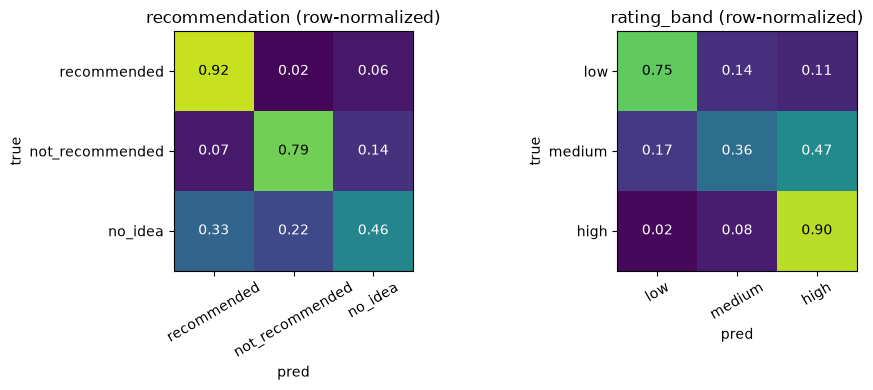

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (task, (col, classes, _)) in zip(axes, TASKS.items()):
    cm = np.array(results[task]["test"]["confusion_matrix"], dtype=float)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1)
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=30)
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] < .5 else "black")
    ax.set_title(f"{task} (row-normalized)"); ax.set_xlabel("pred"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig(REP/"fig_baseline_confusion.png", dpi=150); plt.show()

In [12]:
terms = np.array(vec.get_feature_names_out())
for task, clf in models.items():
    print("==", task)
    for i, c in enumerate(clf.classes_):
        top = np.argsort(-clf.coef_[i])[:15]
        print(f"  {c}: {list(terms[top])}")

== recommendation
  no_idea: ['شک دارم', 'نبود', 'ویژه تهیه', 'ولی', 'نیستم', 'قیمت بصرفه', 'مطمئن نیستم', 'بسیار معمولی', 'نیست', 'نمیدونم', 'کاملا معمولی', 'اما', 'احتمالا کتاب', 'بسیار ممنونم', 'کیفیت نیست']
  not_recommended: ['افتضاح', 'بدترین', 'افتضاحه', 'اصلا', 'متاسفم', 'راضی نیستم', 'نخرید', 'پشیمونم', 'آشغاله', 'مزخرف', 'نیست', 'آشغال', 'تقلبی', 'نا', 'مرجوع']
  recommended: ['عالیه', 'بهترین', 'خیلی خوبه', 'بد نبود', 'خوبیه', 'بد نیست', 'عاشقش', 'زیبا', 'خیلی خوب', 'خوش', 'اذیت نمیکنه', 'عالین', 'خیلی راضیم', 'حرف نداره', 'خوبی']
== rating_band
  high: ['بهترین', 'بد نبود', 'بد نیست', 'نازک نیست', 'همون چیزی', 'حرف', 'اذیت نمیکنه', 'عاشقش', 'عالی فقط', 'نظیر', 'پاره نمیشه', 'عالیه فقط', 'عالی', 'خشک نمیکنه', 'خراب نمیشه']
  low: ['بدترین', 'افتضاح', 'افتضاحه', 'متاسفم', 'اصلا', 'آشغاله', 'آشغال', 'مزخرف', 'نخرید', 'فاجعه', 'کنم مرسی', 'نبود', 'مرجوع', 'اشغال', 'فرستادن']
  medium: ['کاملا معمولی', 'کاملا معمولیه', 'بسیار معمولی', '20 به', 'معمولی', 'اما', 'معمولیه', 'کیفیت 